Download completed!
Loading dataset...
Dataset loaded successfully!
Valid records: 2049280
Available dates: 2006-12-16 17:24:00 to 2010-11-26 21:02:00
Complete daily records: 1358

Choose prediction type:
1. Specific date
2. Specific month
3. Specific year
Enter 1, 2, or 3: 2
Enter month (MM-YYYY), e.g. 06-2008: 07-2009

Selected period: 2009-07-01 to 2009-07-31
Historical training records: 877
Actual records for comparison: 30
Training sequences: 847

Training LSTM model...
Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0280
Epoch 2/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0122
Epoch 3/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0116
Epoch 4/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0113
Epoch 5/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0113
Epoch 6/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0111
Epoch 7/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0111
Epoch 8/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0110
Epoch 9/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0110
Epoch 10/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0114
Model training completed!

ACTUAL VS PREDICTED ENERGY CONSUMPTION
      Date  Actual_kWh  Predicted_kWh
2009-07-01      20.306      20.556999
2009-07-02      20.710      20.652000
2009-07-03      14.402      20.750000
2009-07-04      20.643      20.856001
2009-07-05      23.512      20.959999
2009-07-06      15.904      21.066999
2009-07-07      18

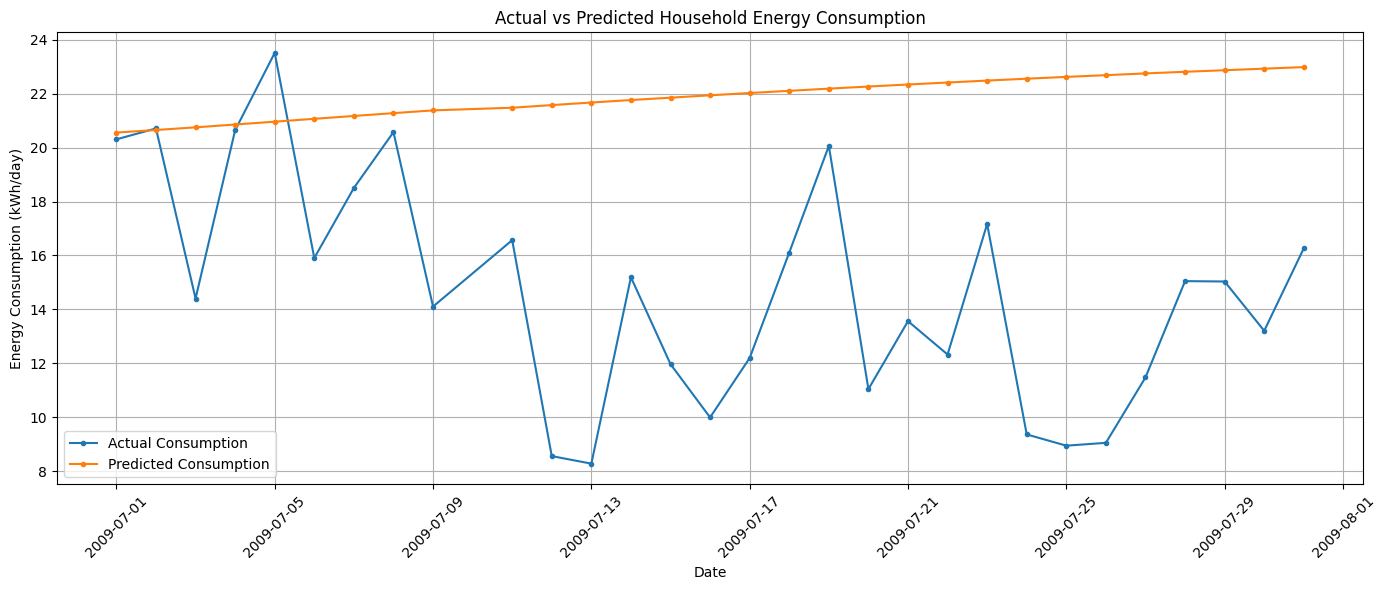

In [10]:


# 1. Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
import zipfile
import os

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping



url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00235/household_power_consumption.zip"

zip_path = "/content/power.zip"
extract_path = "/content/power_data"

print("Downloading dataset...")

urllib.request.urlretrieve(url, zip_path)

print("Download completed!")

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

file_path = os.path.join(
    extract_path,
    "household_power_consumption.txt"
)



print("Loading dataset...")

df = pd.read_csv(
    file_path,
    sep=";",
    na_values="?",
    low_memory=False
)

df["DateTime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True,
    errors="coerce"
)

df["Global_active_power"] = pd.to_numeric(
    df["Global_active_power"],
    errors="coerce"
)

df = df.dropna(
    subset=["DateTime", "Global_active_power"]
)

df = df.sort_values("DateTime")

print("Dataset loaded successfully!")
print("Valid records:", len(df))
print("Available dates:",
      df["DateTime"].min(),
      "to",
      df["DateTime"].max())


# 4. Calculate daily energy consumption

# Power is measured in kW.
# Convert each one-minute reading into kWh.

df["Energy_kWh"] = df["Global_active_power"] / 60

daily = (
    df.set_index("DateTime")["Energy_kWh"]
      .resample("D")
      .sum(min_count=1)
)

# Keep only complete days with all 1440 minute readings.
# This avoids comparing daily totals with incomplete days.

valid_counts = (
    df.set_index("DateTime")["Global_active_power"]
      .resample("D")
      .count()
)

daily = daily[valid_counts == 1440].dropna()

daily.name = "Actual_kWh"

print("Complete daily records:", len(daily))


# 5. Select the prediction period

print("\nChoose prediction type:")
print("1. Specific date")
print("2. Specific month")
print("3. Specific year")

choice = input("Enter 1, 2, or 3: ").strip()

if choice == "1":

    date_input = input(
        "Enter date (DD-MM-YYYY), e.g. 15-06-2008: "
    )

    target_start = pd.to_datetime(
        date_input,
        format="%d-%m-%Y"
    )

    target_end = target_start

elif choice == "2":

    month_input = input(
        "Enter month (MM-YYYY), e.g. 06-2008: "
    )

    target_start = pd.to_datetime(
        "01-" + month_input,
        format="%d-%m-%Y"
    )

    target_end = target_start + pd.offsets.MonthEnd(0)

elif choice == "3":

    year_input = int(
        input("Enter year, e.g. 2008: ")
    )

    target_start = pd.Timestamp(
        year=year_input,
        month=1,
        day=1
    )

    target_end = pd.Timestamp(
        year=year_input,
        month=12,
        day=31
    )

else:
    raise ValueError("Invalid choice. Enter 1, 2, or 3.")


# 6. Select historical and actual data

if target_start < daily.index.min():
    raise ValueError(
        "No historical records are available before this period."
    )

if target_end > daily.index.max():
    raise ValueError(
        "The selected period extends beyond the available dataset."
    )

# Only records strictly before the requested period are used.

train_data = daily[daily.index < target_start]

# Actual readings are reserved for comparison.

actual_period = daily[
    (daily.index >= target_start) &
    (daily.index <= target_end)
]

if len(actual_period) == 0:
    raise ValueError(
        "No complete daily records exist in the selected period."
    )

if len(train_data) < 60:
    raise ValueError(
        "Insufficient historical data for reliable LSTM training. "
        "Choose a later date, month, or year."
    )

print("\nSelected period:",
      target_start.date(),
      "to",
      target_end.date())

print("Historical training records:", len(train_data))
print("Actual records for comparison:", len(actual_period))


# ============================================================
# 7. Normalize historical data
# ============================================================

scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(
    train_data.values.reshape(-1, 1)
)


# 8. Create sequences using previous 30 days

window = 30

X_train = []
y_train = []

for i in range(window, len(train_scaled)):

    X_train.append(
        train_scaled[i-window:i]
    )

    y_train.append(
        train_scaled[i]
    )

X_train = np.array(X_train)
y_train = np.array(y_train)

print("Training sequences:", len(X_train))


# 9. Build and train the LSTM model

model = Sequential([
    LSTM(32, input_shape=(window, 1)),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse"
)

early_stop = EarlyStopping(
    monitor="loss",
    patience=2,
    restore_best_weights=True
)

print("\nTraining LSTM model...")

model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

print("Model training completed!")


# 10. Predict the selected period

history = list(train_scaled.flatten())

predictions = []

for i in range(len(actual_period)):

    last_30 = np.array(
        history[-window:]
    ).reshape(1, window, 1)

    pred = model.predict(
        last_30,
        verbose=0
    )[0, 0]

    predictions.append(pred)

    # Use the prediction to forecast the next day.

    history.append(pred)


# Convert predictions back to kWh.

predictions = scaler.inverse_transform(
    np.array(predictions).reshape(-1, 1)
).flatten()


# 11. Compare actual and predicted consumption

results = pd.DataFrame({
    "Date": actual_period.index,
    "Actual_kWh": actual_period.values,
    "Predicted_kWh": predictions
})

mae = mean_absolute_error(
    results["Actual_kWh"],
    results["Predicted_kWh"]
)

rmse = np.sqrt(
    mean_squared_error(
        results["Actual_kWh"],
        results["Predicted_kWh"]
    )
)

print("\nACTUAL VS PREDICTED ENERGY CONSUMPTION")

print(results.round(3).to_string(index=False))

print("\nMean Absolute Error (MAE):",
      round(mae, 3), "kWh/day")

print("Root Mean Squared Error (RMSE):",
      round(rmse, 3), "kWh/day")


# 12. Plot actual vs predicted consumption

plt.figure(figsize=(14, 6))

plt.plot(
    results["Date"],
    results["Actual_kWh"],
    label="Actual Consumption",
    marker="o",
    markersize=3
)

plt.plot(
    results["Date"],
    results["Predicted_kWh"],
    label="Predicted Consumption",
    marker="o",
    markersize=3
)

plt.xlabel("Date")
plt.ylabel("Energy Consumption (kWh/day)")

plt.title(
    "Actual vs Predicted Household Energy Consumption"
)

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()